planck function, stellar initial mass function(IMF), use of trapezoidal approximation and Gaussian quadrature

In [5]:
import numpy as np 
from scipy import integrate
from astropy.modeling.models import BlackBody
from astropy import units as u
import matplotlib.pyplot as plt

Finding Bolometric Luminosity using Planck Function: 
 We can find out the total intensity (bolometric) from this object, by integrating the Planck function. The simplest way to do this is by approximating the integral using the trapezoid rule.

Using the frequency definition of Planck function

In [ ]:
#consider temperature of a blackbody be 5000 K
bb =BlackBody(5000.0*u.Kelvin)

# numpy arrray * unit of tetra Hz
nu =np.linspace(1.0,3000.0, 1000) * u.THz

#integrate bb over nu
BB = bb(nu)

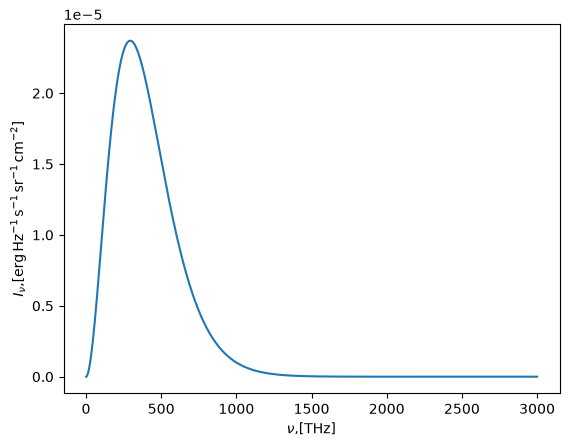

In [18]:
plt.plot(nu, BB)
# we gotta use latex for units
plt.xlabel(r"$\nu $,[{0:latex_inline}]".format(nu.unit))
plt.ylabel(r"$I_{\nu} $,"+"[{0:latex_inline}]".format(BB.unit))
plt.show()


In [19]:
np.trapezoid(x=nu, y=BB).to("erg s-1 cm-2 sr-1")

<Quantity 1.12808487e+10 erg / (s sr cm2)>

In [ ]:
# lam= lambda( wavelength)
# make a list of evenly spaced 1000 wavelengths
# it takes frequency "nu" find max and min of it in function and concerts to "AA"(angstroms)

#equivalencies convert different units 

lam= np.linspace(
    nu.max().to(u.AA,equivalencies=u.spectral()),
    nu.min().to(u.AA,equivalencies=u.spectral()),
    1000,
)
#bb_lam again integrate blackbody function over lam(wavelengths)

bb_lam =BlackBody(bb.temperature, scale=1.0 * u.erg / (u.cm**2 * u.AA * u.s * u.sr))
bb5000K_lam= bb_lam(lam)


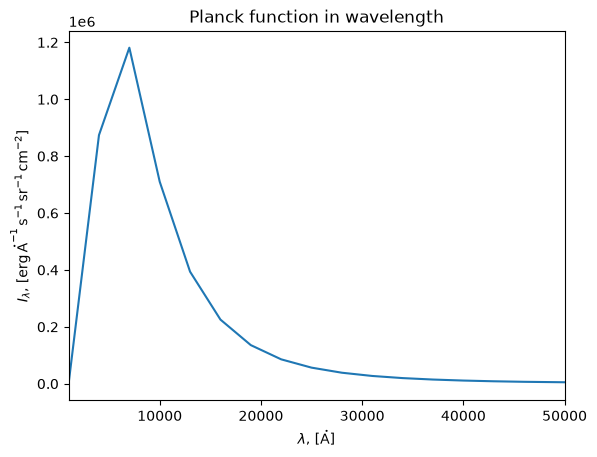

In [21]:
plt.plot(lam, bb5000K_lam)
plt.xlim([1.0e3, 5.0e4])
plt.xlabel(r"$\lambda$, [{0:latex_inline}]".format(lam.unit))
plt.ylabel(r"$I_{\lambda}$, " + "[{0:latex_inline}]".format(bb5000K_lam.unit))
plt.title("Planck function in wavelength")
plt.show()

In [26]:
# trapezoid is typically used to find in these cases for  calculating energy and total brightness(flux)

Luminosity=np.trapezoid(x=lam, y=bb5000K_lam).to("erg s-1 cm-2 sr-1")
print(f"The luminosity is : {Luminosity}")

The luminosity is : 11467760089.73913 erg / (s sr cm2)


Astropy doesnot explicitly support constructing synthetic observations of models like blackbody curves. Library synphot can help to perform tasks like turning spectra into visual magnitudes by convolving with a filter curve.

Initial Mass Function(IMF)
This function tells us how mass is distributed among stars.

Note: If we count the stars that have been born recently from a cloud of gas, their distribution of mass will follow IMF

In [ ]:
#it defines Power law probability density function(PDF)
# this is the way to define initial mass function
# these parameters gamma , and B are from the function
# x= stellar mass
class PowerLawPDF(object):
    def __init__(self, gamma, B=1.0):
        self.gamma = gamma
        self.B = B

    def __call__(self, x):
        return x**self.gamma / self.B

# Section:2

Now we can use our new class to normalize our IMF given the mass bounds.

Use of Gaussian quadrature(quad) to find integral.
Quad provides numerical value and its uncertainty.

Renormalization here mean adjusting constant B such that the integral of the function just give total area under the curve = 1.

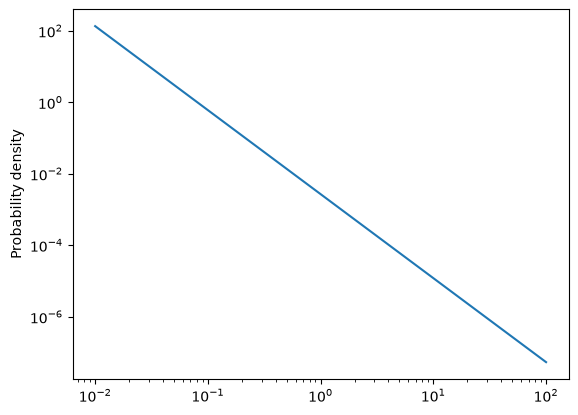

In [ ]:
salpeter= PowerLawPDF(gamma=-2.35)

# integrate.quad(salpeter, a=0.01, b=100) calculates area under the curve
# a=0.01 means 0.01 times solar mass to 100  times solar mass
# quad gave one value salpeter.B and _ error (which is neglected)

salpeter.B,_=integrate.quad(salpeter, a=0.01, b=100.0)
# this creates 100 mass values spaced out logarithmically
m_grid = np.logspace(-2.0, 2.0, 100)
# plot normalizing results; loglog convert both x and y values to logarithmic
plt.loglog(m_grid, salpeter(m_grid))
plt.xlabel=(r"Stellar mass[$ M_{\odot}$]")
plt.ylabel("Probability density")
plt.show()

To calculate how many more M stars are there than O stars:
M stars : Stars with mass < 0.6 * solar mass
O stars: Stars with mass > 15 * solar mass

In [39]:
#no. of m(dwarf stars)
n_m,_= integrate.quad(salpeter, a=0.01, b=0.6)
n_o,_ =integrate.quad(salpeter, a=15.0, b=100.0)
print(n_m/n_o)

20936.017868337385


There are almost 21000 as many low-mass stars born as there are high mass stars.

 Since this argument is unchanged throughout the integral, it is passed into the tuple args within quad. It’s important that there is only one argument that changes over the integral, and that it is the first argument that the function being integrated accepts.

In [ ]:
#IMF_m calculates the mass of m stars
def IMF_m(m, imf):
    return imf(m) * m
#m_m= total mass of M dwarf stars
#m_o= total mass of O type stars

m_m,_=integrate.quad(IMF_m, a=0.01, b=0.6, args=(salpeter,))
m_o,_=integrate.quad(IMF_m, a=15.0, b=100.0, args=(salpeter,))

m_m/m_o

20.29197629920483

The previous results means that in cosmos dwarf stars have more mass than that attributed to o type stars

# Section 3: Astropy coordinates (astropy.coordinates)

Best way to use coordinates is to use SkyCord class.

In [49]:
# to create SkyCord:
from astropy import units as u
from astropy.coordinates import SkyCoord
c= SkyCoord(ra=10.625*u.degree, dec=41.2*u.degree, frame= 'icrs')

In [53]:
c = SkyCoord(10.625, 41.2, frame ='icrs', unit='deg')
c = SkyCoord('00h42m30s','+41d12m00s', frame='icrs')
c = SkyCoord('00h42.5m','+41d12m')
c = SkyCoord('00:42.5 +41:12', unit=(u.hourangle, u.deg))
c

<SkyCoord (ICRS): (ra, dec) in deg
    (10.625, 41.2)>

array coordinates: multiple coordinates at once

In [54]:
import numpy as np
c=SkyCoord(ra=[10,11,12,13]*u.degree, dec=[41, -5, 42,0]*u.degree)
c

<SkyCoord (ICRS): (ra, dec) in deg
    [(10., 41.), (11., -5.), (12., 42.), (13.,  0.)]>

In [55]:
c[1]

<SkyCoord (ICRS): (ra, dec) in deg
    (11., -5.)>

In [56]:
c.reshape(2,2)

<SkyCoord (ICRS): (ra, dec) in deg
    [[(10., 41.), (11., -5.)],
     [(12., 42.), (13.,  0.)]]>

In [57]:
np.roll(c,1)

<SkyCoord (ICRS): (ra, dec) in deg
    [(13.,  0.), (10., 41.), (11., -5.), (12., 42.)]>

coordinate access from the coordinate object created

In [58]:
c = SkyCoord(ra=10.68458*u.degree, dec=41.26917*u.degree)
c.ra
c.ra.hour
c.ra.hms
c.dec
c.dec.degree
c.dec.radian

np.float64(0.7202828960652683)

In [59]:
c = SkyCoord(ra=10.68458*u.degree, dec=41.26917*u.degree)
c.to_string('decimal')
c.to_string('dms')
c.to_string('hmsdms')

'00h42m44.2992s +41d16m09.012s'

In [60]:
# converting to a new  coordinate
c_icrs = SkyCoord(ra=10.68458*u.degree, dec=41.26917*u.degree, frame='icrs')
c_icrs.galactic


<SkyCoord (Galactic): (l, b) in deg
    (121.17424181, -21.57288557)>

In [61]:
c_fk5 = c_icrs.transform_to('fk5')  # c_icrs.fk5 does the same thing
c_fk5


<SkyCoord (FK5: equinox=J2000.000): (ra, dec) in deg
    (10.68459154, 41.26917146)>

In [ ]:
# fk5 (fifth fundamental Catelogue)
from astropy.coordinates import FK5
#equinox(1975)
c_fk5.transform_to(FK5(equinox='J1975'))  # precess to a different equinox

<SkyCoord (FK5: equinox=J1975.000): (ra, dec) in deg
    (10.34209135, 41.13232112)>

 When transforming to/from other frames the earth rotation values are automatically downloaded from the International Earth Rotation and Reference Systems (IERS) service when required.

To use other coordinate system than default spherical, we specify which coordinate we want to work with using: representation_type='cartesian'

In [64]:
c= SkyCoord(x=1,y=2,z=3, unit='kpc', representation_type='cartesian')
c

<SkyCoord (ICRS): (x, y, z) in kpc
    (1., 2., 3.)>

In [65]:
c.x,c.y,c.z

(<Quantity 1. kpc>, <Quantity 2. kpc>, <Quantity 3. kpc>)

We can calculate distance from origin of the used coordinate system. Origin may be centered on earth, centered on solar system barycenter, depending uponthe coordinates used. 

In [68]:
c = SkyCoord(ra=10.68458*u.degree, dec=41.26917*u.degree, distance=770*u.kpc)
a=c.cartesian.x
b=c.cartesian.y
o=c.cartesian.z
print(a,b,o)

568.7128654235232 kpc 107.3008974042025 kpc 507.88994291875713 kpc


In [ ]:
c1 = SkyCoord(ra=10*u.degree, dec=9*u.degree, distance=10*u.pc, frame='icrs')
c2 = SkyCoord(ra=11*u.degree, dec=10*u.degree, distance=11.5*u.pc, frame='icrs')
c1.separation_3d(c2)
#can be used to find the distance between two stars

<Distance 1.52286024 pc>

SkyCoord defines a number of convenience methods that support, for example, computing on-sky (i.e., angular) and 3D separations between two coordinates.

In [70]:
c1 = SkyCoord(ra=10*u.degree, dec=9*u.degree, frame='icrs')
c2 = SkyCoord(ra=11*u.degree, dec=10*u.degree, frame='fk5')
c1.separation(c2)  # Differing frames handled correctly

<Angle 1.40453359 deg>

Cross matching: 


read in coordinates from a catalog...

 idx= index= row number or postion of the matching object inside "catelog_c"
#sep=separation angular in sky between target star and found star



In [77]:
target_c = SkyCoord(ra=10*u.degree, dec=9*u.degree, frame='icrs')
# read in coordinates from a catalog...
catalog_c = ...
idx, sep, _= target_c.match_to_catalog_sky(catalog_c)

TypeError: Can only get separation to another SkyCoord or a coordinate frame with data

To retrieve coordinates for a particular name:

In [78]:
SkyCoord.from_name("PSR J1012+5307")

<SkyCoord (ICRS): (ra, dec) in deg
    (153.1393106, 53.1173746)>

In [ ]:
d= SkyCoord.from_name("NGC 7039")

In [88]:
d.ra

<Longitude 317.66291667 deg>

In [89]:
d.ra.hour

np.float64(21.177527778000005)

For object name embedded in the catelog:

In [90]:
SkyCoord.from_name("CRTS SSS100805 J194428-420209", parse=True)

<SkyCoord (ICRS): (ra, dec) in deg
    (296.11666667, -42.03583333)>

This method compromises sub-arcsecond accuracy

For sites (primarily observatories) on the Earth, astropy.coordinates provides a quick way to get an EarthLocation - the of_site() classmethod:

In [91]:
from astropy.coordinates import EarthLocation
apo = EarthLocation.of_site('Apache Point Observatory')
apo

<EarthLocation (-1463969.30185172, -5166673.34223433, 3434985.71204565) m>

In [93]:
EarthLocation.get_site_names()

['ALMA',
 'AO',
 'ARCA',
 'ASKAP',
 'ATA',
 'ATCA',
 'ATST',
 'Allen Telescope Array',
 'Anderson Mesa',
 'Anglo-Australian Observatory',
 'Apache Point',
 'Apache Point Observatory',
 'Arecibo',
 'Arecibo Observatory',
 'Astroparticle Research with Cosmics in the Abyss',
 'Atacama Large Millimeter Array',
 'Australia Telescope Compact Array',
 'Australian Square Kilometre Array Pathfinder',
 'BAO',
 'BBSO',
 'Beijing XingLong Observatory',
 'Big Bear Solar Observatory',
 'Black Moshannon Observatory',
 'CAHA',
 'CAHA',
 'CHARA',
 'CHIME',
 'Canada-France-Hawaii Telescope',
 'Canadian Hydrogen Intensity Mapping Experiment',
 'Catalina Observatory',
 'Catalina Observatory: 61 inch telescope',
 'Centro Astronomico Hispano-Aleman, Almeria',
 'Cerro Armazones Observatory',
 'Cerro Pachon',
 'Cerro Paranal',
 'Cerro Tololo',
 'Cerro Tololo Interamerican Observatory',
 'Cima Ekar 182 cm Telescope',
 'Cima Ekar Observing Station',
 'Ckoirama',
 'Ckoirama Observatory',
 'DCT',
 'DKIST',
 'DOT'

In [94]:
EarthLocation.of_address('1002 Holy Grail Court, St. Louis, MO')

<EarthLocation (-26769.86384852, -4997007.70924596, 3950273.57970707) m>

In [95]:
from astropy.time import Time
obstime = Time('2017-2-14')
target = SkyCoord.from_name('M31')
keck = EarthLocation.of_site('Keck')
target.radial_velocity_correction(obstime=obstime, location=keck).to('km/s')

<Quantity -22.35980045 km / s>

In [96]:
import datetime
from zoneinfo import ZoneInfo
tz = ZoneInfo('America/Phoenix')
dt = datetime.datetime(2021, 4, 12, 20, 0, 0, tzinfo=tz)

Proper motions and radial velocities:

In [97]:
sc = SkyCoord(1*u.deg, 2*u.deg, radial_velocity=20*u.km/u.s)
sc

<SkyCoord (ICRS): (ra, dec) in deg
    (1., 2.)
 (radial_velocity) in km / s
    (20.,)>

Sometimes when we have incomplete information about objects, eg some have distances while others have not. Use "Masked" class for using masks in such purposes.


In [103]:
from astropy.utils.masked import Masked
distance= Masked([0.1,np.nan]*u.kpc,mask=[False,True])
distance
sc= SkyCoord([1.,2.]*u.hourangle,[3.,4.]*u.deg, distance=distance)
sc

<SkyCoord (ICRS): (ra, dec, distance) in (deg, deg, kpc)
    [(15., 3., 0.1), (30., 4., ———)]>

In [104]:
sc.separation(sc[0])


<MaskedAngle [ 0.        , 15.00502838] deg>

In [105]:
sc.separation_3d(sc[0])
gcrs = sc.gcrs
gcrs

/home/user/miniconda3/lib/python3.14/site-packages/astropy/utils/masked/core.py:863: RuntimeWarning: invalid value encountered in ld
  result = getattr(ufunc, method)(*unmasked, **kwargs)
/home/user/miniconda3/lib/python3.14/site-packages/astropy/utils/masked/core.py:863: RuntimeWarning: invalid value encountered in anp
  result = getattr(ufunc, method)(*unmasked, **kwargs)


<SkyCoord (GCRS: obstime=J2000.000, obsgeoloc=(0., 0., 0.) m, obsgeovel=(0., 0., 0.) m / s): (ra, dec, distance) in (deg, deg, kpc)
    [(15.00054403, 2.99988395, 0.1), (        ———,        ———, ———)]>

In [106]:
gcrs.unmasked

<SkyCoord (GCRS: obstime=J2000.000, obsgeoloc=(0., 0., 0.) m, obsgeovel=(0., 0., 0.) m / s): (ra, dec, distance) in (deg, deg, kpc)
    [(15.00054403, 2.99988395, 0.1), (        nan,        nan, nan)]>

In [114]:
!pip install astroquery

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 6.1 MB/s  0:00:01m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 4.8 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [astroquery]6 [astroquery]


In [115]:
import matplotlib.pyplot as plt

%matplotlib inline
import numpy as np

from astropy import units as u
from astropy.coordinates import SkyCoord, Distance
from astropy.table import QTable

from astroquery.gaia import Gaia

Gaia.ROW_LIMIT = 10000  # Set the row limit for returned data

To get started, let’s assume that we want to create a SkyCoord object for the center of the open star cluster NGC 188 so that later we can query and retrieve stars that might be members of the cluster. 

In [116]:
ngc188_center = SkyCoord(12.11 * u.deg, 85.26 * u.deg)
ngc188_center

<SkyCoord (ICRS): (ra, dec) in deg
    (12.11, 85.26)>

In [117]:
SkyCoord("00h48m26.4s", "85d15m36s", frame="icrs")

<SkyCoord (ICRS): (ra, dec) in deg
    (12.11, 85.26)>

In [118]:
ngc188_center.to_string(style="hmsdms", sep=":", precision=1)

'00:48:26.4 +85:15:36.0'

In [120]:
ngc188_center.to_string(style="hmsdms", sep=":", precision=1)

'00:48:26.4 +85:15:36.0'

In [125]:
ngc188_center = SkyCoord.from_name("NGC 188")
ngc188_center

<SkyCoord (ICRS): (ra, dec) in deg
    (11.79791667, 85.24388889)>

In [126]:
ngc188_center.ra, ngc188_center.dec

(<Longitude 11.79791667 deg>, <Latitude 85.24388889 deg>)

In [127]:
type(ngc188_center.ra), type(ngc188_center.dec)

(astropy.coordinates.angles.core.Longitude,
 astropy.coordinates.angles.core.Latitude)

In [128]:
(
    ngc188_center.ra.to(u.hourangle),
    ngc188_center.ra.to(u.radian),
    ngc188_center.ra.to(u.degree),
)

(<Longitude 0.78652778 hourangle>,
 <Longitude 0.20591249 rad>,
 <Longitude 11.79791667 deg>)

In [129]:
(ngc188_center.ra.hour, ngc188_center.ra.radian, ngc188_center.ra.degree)

(np.float64(0.7865277780000001),
 np.float64(0.2059124907674253),
 np.float64(11.79791667))

Note that for querying a data base; we must have a single star first. Find its SkyCoord first, and consider those coordinates to be center.

Here, we will use the SkyCoord object ngc188_center to select sources from the Gaia Data Release 2 catalog around the position of the center of NGC 188 to look for stars that might be members of the star cluster.

In [ ]:
job =Gaia.cone_search_async(ngc188_center, radius=0.5* u.deg)
ngc188_table = job.get_results()

# only keep stars for which brightness is greater than G=19;


INFO: Query finished. [astroquery.utils.tap.core]


NameError: name 'ngc_table' is not defined

In [144]:
ngc188_table = QTable.read("gaia_results.fits")

In [147]:
gc_table= ngc188_table[ngc188_table["phot_g_mean_mag"] > 19 *u.mag]


In [148]:
cols = [
    "source_id",
    "ra",
    "dec",
    "parallax",
    "parallax_error",
    "pmra",
    "pmdec",
    "radial_velocity",
    "phot_g_mean_mag",
    "phot_bp_mean_mag",
    "phot_rp_mean_mag",
]
ngc188_table[cols].write("gaia_results.fits", overwrite=True)

In [149]:
len(ngc188_table)

10000

In [151]:
ngc188_table["ra"]

<Quantity [11.77583082, 11.83025781, 11.78143038, ..., 14.41522696,
            9.97648309, 14.90600519] deg>

In [152]:
ngc188_table["dec"]

<Quantity [85.24193164, 85.24362655, 85.24714775, ..., 85.68315506,
           84.78485861, 84.83926755] deg>

In [153]:
ngc188_gaia_coords = SkyCoord(ngc188_table["ra"], ngc188_table["dec"])
ngc188_gaia_coords

<SkyCoord (ICRS): (ra, dec) in deg
    [(11.77583082, 85.24193164), (11.83025781, 85.24362655),
     (11.78143038, 85.24714775), ..., (14.41522696, 85.68315506),
     ( 9.97648309, 84.78485861), (14.90600519, 84.83926755)]>

In [154]:
ngc188_center= SkyCoord.from_name("NGC188")

Always check your answer against SIMBAD data

In [156]:
ngc188_center.to_string(style="hmsdms", sep=":", precision=1)

'00:47:11.5 +85:14:38.0'

In [ ]:
#separation of each stars with thengc center
ngc188_gaia_coords.separation(ngc188_center)

<Angle [0.0026806 , 0.00269443, 0.00353376, ..., 0.485491  , 0.48550023,
        0.48553984] deg>

In [158]:
ngc188_center_3d =SkyCoord(12.11 * u.deg, 85.26 * u.deg, distance=1.96 *u.kpc)